# **Лабораторная 3. Метод главных компонент**

> - **Предмет**: Математические методы анализа экономических процессов
> - **Студент**: Руденко Андрей Артемович
> - **Группа**: М9125-01.04.02МКТ

## Цель работы
1. Построить главные компоненты набора данных из лабораторной 1 через собственные числа и собственные векторы матрицы ковариации
2. Разделить виды заболеваний на группы с помощью метода главных компонент

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

## 3.1. Главные компоненты набора данных из лабораторной 1

### Данные *(Вариант 16)*

In [2]:
data = pd.DataFrame({'X1': [19, 21, 34, 17], 'X2': [31, 33, 60, 37]}, index=[1, 2, 3, 4])
data.columns.name = 'Объект'
data

Объект,X1,X2
1,19,31
2,21,33
3,34,60
4,17,37


### Центрирование

Из каждого признака вычитаю его среднее. Оба признака в одном масштабе, поэтому не стандартизую: компоненты строятся по матрице ковариации центрированных данных.
$$x_c = x - \bar{x}$$

In [3]:
centered = data - data.mean()
centered

Объект,X1,X2
1,-3.75,-9.25
2,-1.75,-7.25
3,11.25,19.75
4,-5.75,-3.25


### Матрица ковариации

$$S = \frac{1}{n - 1} X_c^T X_c$$

In [4]:
cov = centered.T @ centered / (len(data) - 1)
cov

Объект,X1,X2
Объект,,
X1,58.916667,96.083333
X2,96.083333,179.583333


### Собственные числа и собственные векторы

Собственные векторы матрицы ковариации — направления главных компонент, собственные числа — дисперсия данных вдоль этих направлений. Компоненты упорядочиваю по убыванию собственного числа.
$$S v = \lambda v$$

In [5]:
values, vectors = np.linalg.eigh(cov.to_numpy())
order = np.argsort(values)[::-1]
values, vectors = values[order], vectors[:, order]

print('Собственные числа:', values.round(2))
print('Доля дисперсии:', (values / values.sum()).round(3))
pd.DataFrame(vectors, index=data.columns, columns=['PC1', 'PC2'])

Собственные числа: [232.71   5.79]
Доля дисперсии: [0.976 0.024]


,PC1,PC2
Объект,,
X1,0.483849,-0.875152
X2,0.875152,0.483849


### Проекция в пространство главных компонент

$$Z = X_c V$$

In [6]:
projection = pd.DataFrame(centered.to_numpy() @ vectors, index=data.index, columns=['PC1', 'PC2'])
print('Дисперсия по компонентам:', projection.var().round(2).tolist())
projection

Дисперсия по компонентам: [232.71, 5.79]


,PC1,PC2
1,-9.909585,-1.193785
2,-7.191584,-1.976390
3,22.727543,-0.289438
4,-5.626374,3.459612


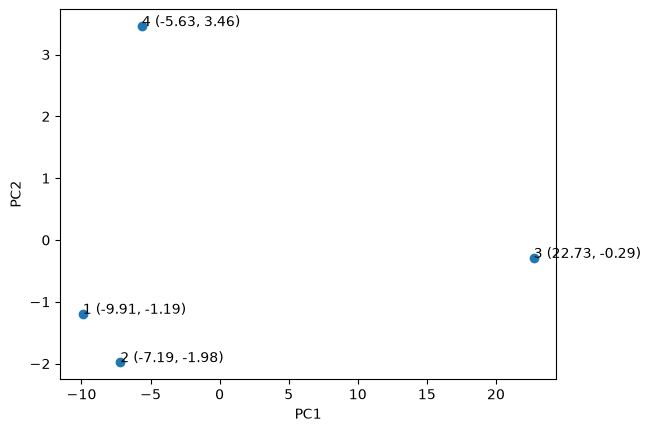

In [7]:
plt.scatter(projection['PC1'], projection['PC2'])
for i in projection.index:
    plt.text(projection['PC1'][i], projection['PC2'][i], f"{i} ({projection['PC1'][i]:.2f}, {projection['PC2'][i]:.2f})")
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

### Результат

Первая главная компонента забирает 97.6% дисперсии, вторая — 2.4%. Признаки X1 и X2 растут вместе, поэтому PC1 описывает общий «размер» объекта. По PC1 объект 3 далеко отстоит от остальных, что совпадает с результатом кластеризации в лабораторной 1. Дисперсии проекций совпали с собственными числами 232.71 и 5.79.

## 3.2. Группировка видов заболеваний методом главных компонент

### Данные *(Вариант 16)*

В файле к варианту — заболеваемость населения по основным классам болезней за 2010–2022 гг. Беру показатели на 1000 человек населения, строку «Все болезни» исключаю, т.к. это сумма остальных строк.

In [8]:
raw = pd.read_excel('К вариантам 15_16.ods', engine='odf', header=None)
ill = raw.iloc[28:44].set_index(0)
ill.columns = list(raw.iloc[5, 1:].astype(int))
ill = ill.astype(float)

names = pd.Series(ill.index.str.replace('1)', '').str.strip(), index=range(1, len(ill) + 1))
ill.index = names.index
years = list(ill.columns)
names

1         некоторые инфекционные и паразитарные болезни
2                                       новообразования
3     болезни крови, кроветворных органов и отдельны...
4     болезни эндокринной системы, расстройства пита...
5                               болезни нервной системы
6             болезни глаза и его придаточного аппарата
7                   болезни уха и сосцевидного отростка
8                        болезни системы кровообращения
9                               болезни органов дыхания
10                          болезни органов пищеварения
11                   болезни кожи и подкожной клетчатки
12    болезни костно-мышечной системы и соединительн...
13                          болезни мочеполовой системы
14    осложнения беременности, родов и послеродового...
15    врожденные аномалии (пороки развития), деформа...
16    травмы, отравления и некоторые другие последст...
Name: 0, dtype: str

In [9]:
ill

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
1,39.2,35.9,33.9,35.8,34.6,31.5,33.1,31.8,31.7,35.1,28.0,26.9,35.9
2,9.6,10.5,10.5,10.0,10.0,10.2,10.4,11.2,11.4,13.2,10.3,10.6,13.1
3,4.2,3.9,3.7,3.7,3.4,3.6,2.5,2.4,2.8,2.5,2.2,2.6,2.6
4,7.5,7.6,7.4,7.8,7.7,7.7,7.1,8.9,6.7,7.3,6.7,6.2,7.8
5,14.9,14.8,14.1,15.1,16.9,12.4,13.1,13.6,14.7,16.2,15.4,16.7,18.1
6,27.6,27.6,25.9,25.4,26.2,22.4,21.2,22.9,24.7,23.7,19.5,18.3,16.3
7,24.0,22.8,21.6,21.6,19.0,18.9,16.0,16.7,20.4,19.3,18.9,17.3,17.7
8,19.5,18.9,16.6,17.1,19.7,20.6,23.5,22.5,25.8,26.1,22.3,23.4,29.0
9,308.7,343.0,325.5,337.8,320.4,310.8,328.8,331.1,345.1,330.3,359.6,397.2,400.4
10,37.5,34.4,26.2,24.7,23.7,21.7,19.8,21.0,26.8,30.4,27.7,30.1,33.3


### Кластеризация по всем годам

Все годы измерены в одних единицах и одном масштабе, поэтому данные не стандартизую. Число кластеров выбираю методом локтя.

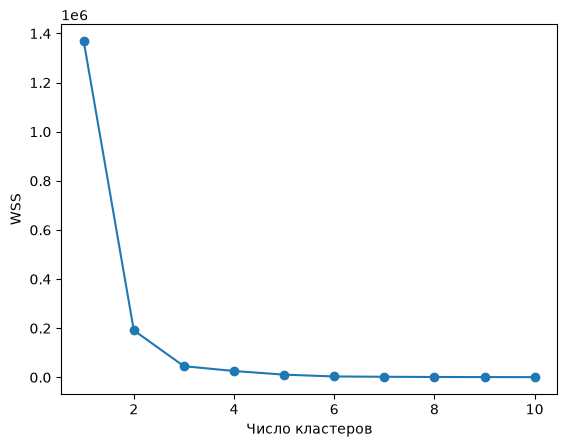

In [10]:
wss = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(ill[years]).inertia_ for k in range(1, 11)]
plt.plot(range(1, 11), wss, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('WSS')
plt.show()

Излом на графике — при 3 кластерах, дальше WSS почти не убывает. Беру 3 кластера.

In [11]:
k = 3
ill['cluster'] = KMeans(n_clusters=k, n_init=10, random_state=42).fit(ill[years]).labels_ + 1

for c in range(1, k + 1):
    print(f'Кластер {c}:')
    for i in ill.index[ill['cluster'] == c]:
        print(f'  {i}. {names[i]}')

Кластер 1:
  1. некоторые инфекционные и паразитарные болезни
  2. новообразования
  3. болезни крови, кроветворных органов и отдельные нарушения, вовлекающие иммунный механизм
  4. болезни эндокринной системы, расстройства питания и нарушения обмена веществ
  5. болезни нервной системы
  6. болезни глаза и его придаточного аппарата
  7. болезни уха и сосцевидного отростка
  8. болезни системы кровообращения
  10. болезни органов пищеварения
  11. болезни кожи и подкожной клетчатки
  12. болезни костно-мышечной системы и соединительной ткани
  13. болезни мочеполовой системы
  15. врожденные аномалии (пороки развития), деформации и хромосомные нарушения
Кластер 2:
  9. болезни органов дыхания
Кластер 3:
  14. осложнения беременности, родов и послеродового периода
  16. травмы, отравления и некоторые другие последствия воздействия внешних причин


### Главные компоненты

In [12]:
pca = PCA().fit(ill[years])
pd.DataFrame({'Доля дисперсии': pca.explained_variance_ratio_,
              'Накопленная доля': pca.explained_variance_ratio_.cumsum()},
             index=[f'PC{i}' for i in range(1, len(years) + 1)]).head(5).round(4)

,Доля дисперсии,Накопленная доля
PC1,0.9977,0.9977
PC2,0.0014,0.9991
PC3,0.0004,0.9995
PC4,0.0002,0.9997
PC5,0.0002,0.9999


In [13]:
loadings = pd.DataFrame(pca.components_[:2].T, index=years, columns=['PC1', 'PC2'])
loadings.round(3)

,PC1,PC2
2010,0.252,-0.470
2011,0.275,-0.076
2012,0.264,-0.303
2013,0.274,-0.260
2014,0.260,-0.226
2015,0.250,0.040
2016,0.268,-0.075
2017,0.269,-0.007
2018,0.279,0.122
2019,0.269,-0.163


### Годы, сильнее всего влияющие на разницу между группами

PC1 забирает 99.8% дисперсии, т.е. классы болезней различаются почти только общим уровнем заболеваемости. Накопленная доля после PC1 почти не растёт, поэтому для анализа достаточно одной компоненты. Веса всех лет в PC1 близки (от 0.25 до 0.32), наибольшие — у 2022, 2021 и 2020 гг.: в эти годы разница между классами больше всего, в основном из-за роста болезней органов дыхания (с 330 на 1000 человек в 2019 г. до 400 в 2022 г.). Беру эти 3 года.

[2022, 2021, 2020]


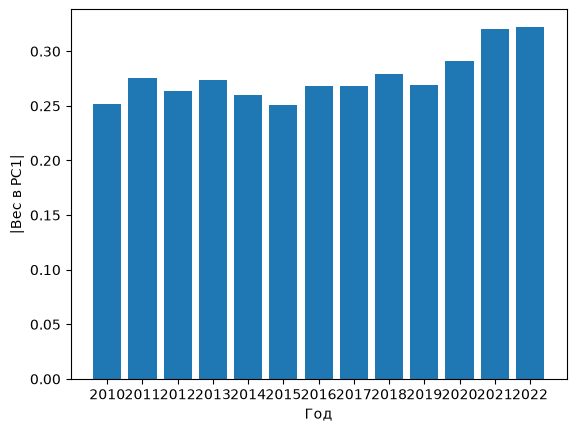

In [14]:
top_years = list(loadings['PC1'].abs().sort_values(ascending=False).index[:3])
print(top_years)

plt.bar([str(y) for y in years], loadings['PC1'].abs())
plt.xlabel('Год')
plt.ylabel('|Вес в PC1|')
plt.show()

### Кластеризация по выбранным годам

In [15]:
ill['cluster_top'] = KMeans(n_clusters=k, n_init=10, random_state=42).fit(ill[top_years]).labels_ + 1

for c in range(1, k + 1):
    print(f'Кластер {c}:')
    for i in ill.index[ill['cluster_top'] == c]:
        print(f'  {i}. {names[i]}')

Кластер 1:
  1. некоторые инфекционные и паразитарные болезни
  2. новообразования
  3. болезни крови, кроветворных органов и отдельные нарушения, вовлекающие иммунный механизм
  4. болезни эндокринной системы, расстройства питания и нарушения обмена веществ
  5. болезни нервной системы
  6. болезни глаза и его придаточного аппарата
  7. болезни уха и сосцевидного отростка
  8. болезни системы кровообращения
  10. болезни органов пищеварения
  11. болезни кожи и подкожной клетчатки
  12. болезни костно-мышечной системы и соединительной ткани
  13. болезни мочеполовой системы
  15. врожденные аномалии (пороки развития), деформации и хромосомные нарушения
Кластер 2:
  9. болезни органов дыхания
Кластер 3:
  14. осложнения беременности, родов и послеродового периода
  16. травмы, отравления и некоторые другие последствия воздействия внешних причин


In [16]:
pd.crosstab(ill['cluster'].rename('Все годы'), ill['cluster_top'].rename('Выбранные годы'))

Выбранные годы,1,2,3
Все годы,,,
1,13,0,0
2,0,1,0
3,0,0,2


### Проекция на главные компоненты

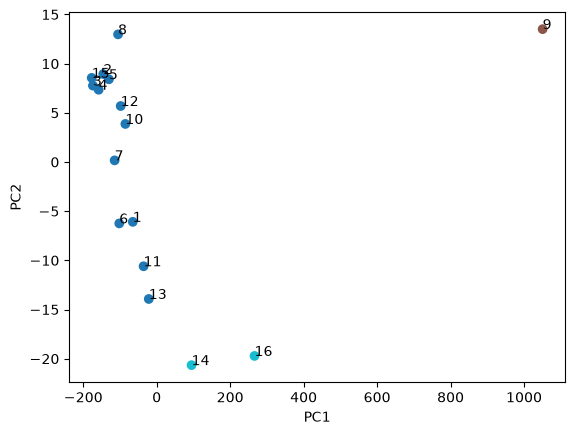

In [17]:
projection = pca.transform(ill[years])
plt.scatter(projection[:, 0], projection[:, 1], c=ill['cluster'], cmap='tab10')
for n, i in enumerate(ill.index):
    plt.text(projection[n, 0], projection[n, 1], i)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

## Вывод

В пункте 3.1 главные компоненты построены через собственные числа и векторы матрицы ковариации. Первая компонента забирает 97.6% дисперсии и отделяет объект 3 от остальных, как и кластеризация в лабораторной 1.

В пункте 3.2 классы болезней делятся на 3 группы: болезни органов дыхания с самым высоким уровнем заболеваемости (300–400 на 1000 человек), травмы и осложнения беременности (от 64 до 135) и остальные 13 классов (не выше 55). Осложнения беременности считаются на 1000 женщин 15–49 лет, поэтому их высокий уровень частично объясняется другой базой расчёта. Первая главная компонента забирает 99.8% дисперсии, т.е. группы различаются прежде всего общим уровнем заболеваемости. Сильнее всего на разницу влияют 2020–2022 гг., когда выросла заболеваемость болезнями органов дыхания. Кластеризация только по этим трём годам дала те же кластеры, что и по всем 13 годам. Вторая компонента отражает изменение во времени: у 2010–2014 гг. отрицательные веса, у 2020–2022 гг. положительные. Выше на графике классы, заболеваемость которыми выросла, например болезни системы кровообращения (с 19.5 до 29.0), ниже — снизившиеся, например болезни мочеполовой системы (с 50.3 до 41.3).